# Case study — decision-tree distributional query

Run the DT approach end-to-end on a dataset of your choice, the same pipeline the
UI (`quaero_ui.py`) uses — both import it from `quaero_core.py`.

1. **Dataset** — point at a CSV; `datasets/metadata.py` supplies its delimiter,
   target(s), id columns and categoricals when it knows the file.
2. **Preprocessing** — drop ids and the *other* declared targets, integer-encode
   categoricals, drop NaN/inf rows, bin the target with Scott's rule.
3. **Index** — purity-grown decision tree over the descriptors.
4. **Query** — specify the target distribution as a mixture, then query by
   cardinality (disjoint subsets under a TVD threshold) or by number of boxes.
5. **Plots** — the specified pdf, and each found subset against the full data,
   as in the UI, plus TVD / JSD / KLD / Hellinger / BC.

Edit the cells marked **✏️**, then run top to bottom.

In [26]:
%matplotlib inline
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from quaero_core import (METADATA, read_dataset, target_candidates, prepare_frame,
                         default_dataset, bin_target, _bin_centers, build_index,
                         make_pdf, target_props, feasibility, find_multiple_subsets,
                         find_multiple_box_subsets, selected_rows, dist_metrics,
                         simplify_rule, rule_to_str, rank_by_rule_length)
from plot_style import apply_style, fig_width, fig_height, text_width, ASPECT, CB_palette
apply_style()                    # design language: plot_style.py
print(f"metadata known for {len(METADATA)} datasets")

metadata known for 2 datasets


In [27]:
# PDF saving: FIG_DIR/{title}_{distribution}_{query}_{detail}.pdf (only when SAVE_PDF)
def _num(v):
    """Number for a file name: 4 significant digits, no dots or minus signs
    (dots break \\includegraphics): 0.15 -> 0p15, -1 -> m1, 1e+05 -> 1e05."""
    s = f"{float(v):.4g}"
    return s.replace("-", "m").replace(".", "p").replace("+", "")

def dist_tag(components):
    """The queried distribution, e.g. weibull-shape15-scale2183p6-loc10000-w1."""
    return "+".join(f"{n}-" + "-".join(f"{k}{_num(v)}" for k, v in params.items())
                    + f"-w{_num(w)}" for n, params, w in components)

def fig_path(*parts):
    """FIG_DIR/{title}_{parts...}.pdf, where title is TITLE or the dataset's name."""
    title = TITLE or name
    return str(Path(FIG_DIR) / ("_".join([title, *map(str, parts)]) + ".pdf"))

def save_pdf(fig, path):
    if SAVE_PDF:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight", format='pdf')
        print(f"saved {path}")

## 1. Dataset ✏️

- `DATASET_PATH` — a CSV/TSV on disk. The file's stem (e.g. `winequality-red`) is
  looked up in `datasets/metadata.py`; unknown files have their separator sniffed.
  Set it to `None` to use the built-in synthetic dataset.
- `TARGET` — `None` picks the first target declared in the metadata (or the first
  non-id column for unknown files). Set it explicitly for multi-target datasets.
- `MAX_ROWS` — optional seeded subsample *after* cleaning, to keep the index build
  quick on large files. `None` keeps every row.

In [28]:
DATASET_PATH = "datasets/factory.csv"
TARGET = 'remaining_useful_life_hours' #'failure_probability'
MAX_ROWS = None
SEED = 0

SAVE_PDF = True      # write every drawn graph to FIG_DIR as a PDF
FIG_DIR = "./figures"
TITLE = None          # {title} in file names; None -> the dataset's name

## 2. Load + preprocess

In [29]:
if DATASET_PATH is None or not Path(DATASET_PATH).exists():
    if DATASET_PATH is not None:
        print(f"!! {DATASET_PATH} not found -- falling back to the SYNTHETIC dataset !!")
    df, TARGET = default_dataset()
    raw, meta, name = df.copy(), {}, "synthetic (default)"
else:
    raw, meta, name = read_dataset(DATASET_PATH)
    cands = target_candidates(raw, meta)
    if TARGET is None:
        TARGET = cands[0]
    if TARGET not in raw.columns:
        raise ValueError(f"TARGET {TARGET!r} not in columns {list(raw.columns)}")
    df = prepare_frame(raw, TARGET, meta)

if MAX_ROWS is not None and len(df) > MAX_ROWS:
    df = df.sample(MAX_ROWS, random_state=SEED).reset_index(drop=True)

# what preprocessing did (mirrors prepare_frame's rules)
dropped_ids    = [c for c in meta.get("id_variables", []) if c in raw.columns]
dropped_tgts   = [c for c in meta.get("target_variable", []) if c in raw.columns and c != TARGET]
encoded        = [c for c in raw.columns if c in df.columns
                  and not pd.api.types.is_numeric_dtype(raw[c])]
desc_cols      = [c for c in df.columns if c != TARGET]

print(f"dataset        : {name}   ({'metadata' if meta else 'no metadata, separator sniffed'})")
if meta:
    print(f"delimiter      : {meta.get('delim')!r}")
    print(f"declared target: {meta.get('target_variable')}")
print(f"target         : {TARGET}")
print(f"raw shape      : {raw.shape}")
print(f"dropped ids    : {dropped_ids or '-'}")
print(f"dropped targets: {dropped_tgts or '-'}   (other declared targets, so they cannot leak)")
print(f"encoded        : {encoded or '-'}   (non-numeric -> integer codes)")
print(f"rows dropped   : {len(raw) - len(df) if MAX_ROWS is None else 'n/a (subsampled)'}   (NaN/inf)")
print(f"final shape    : {df.shape}   -> {len(desc_cols)} descriptors")
df.head()

dataset        : factory   (metadata)
delimiter      : ','
declared target: ['machine_failure', 'failure_type', 'remaining_useful_life_hours', 'machine_health_score', 'failure_probability', 'maintenance_priority']
target         : remaining_useful_life_hours
raw shape      : (100000, 72)
dropped ids    : ['machine_id', 'monitoring_id', 'timestamp']
dropped targets: ['machine_failure', 'failure_type', 'machine_health_score', 'failure_probability', 'maintenance_priority']   (other declared targets, so they cannot leak)
encoded        : ['factory_id', 'production_line', 'machine_type', 'manufacturer', 'model', 'factory_shift', 'last_maintenance_date', 'maintenance_type']   (non-numeric -> integer codes)
rows dropped   : 0   (NaN/inf)
final shape    : (100000, 64)   -> 63 descriptors


,factory_id,production_line,machine_type,manufacturer,model,installation_year,machine_age,machine_capacity,machine_power_kw,machine_weight_kg,...,pump_health,hydraulic_health,electrical_health,cooling_system_health,temperature_anomaly_score,vibration_anomaly_score,pressure_anomaly_score,electrical_anomaly_score,energy_anomaly_score,remaining_useful_life_hours
0,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,67.1,94.2,78.5,74.3,38.4,8.6,15.4,9.0,54.1,14591
1,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,67.1,94.2,78.4,74.3,44.1,17.5,9.8,0.3,44.7,14363
2,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,67.1,94.2,78.4,74.3,38.3,10.7,30.8,3.1,47.2,14639
3,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,67.1,94.2,78.4,74.2,40.5,11.2,14.5,13.8,51.7,14459
4,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,67.1,94.2,78.4,74.2,32.7,22.3,8.6,9.3,52.2,14670


## 3. Build the decision-tree index

index built in 7.89s: 95183 nodes, 47592 leaves, 98 target bins (Scott's rule), N=100000
target range [8856, 1.891e+04], mean 1.339e+04, std 1365
figures/factory_data.pdf
saved figures/factory_data.pdf


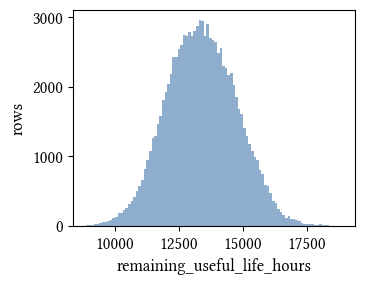

In [30]:
t0 = time.perf_counter()
ix = build_index(df, TARGET)
build_sec = time.perf_counter() - t0

N = len(df)
n_bins = ix["n_bins"]
bin_ids, _ = bin_target(df, TARGET)
centers = _bin_centers(df, TARGET, n_bins)
avail = {b: int((bin_ids == b).sum()) for b in range(n_bins)}
tmin, tmax = float(df[TARGET].min()), float(df[TARGET].max())
edges = np.linspace(tmin, tmax, n_bins + 1)

print(f"index built in {build_sec:.2f}s: {ix['n']} nodes, {len(ix['leaves'])} leaves, "
      f"{n_bins} target bins (Scott's rule), N={N}")
print(f"target range [{tmin:.4g}, {tmax:.4g}], mean {df[TARGET].mean():.4g}, std {df[TARGET].std():.4g}")

fig, ax = plt.subplots(figsize=(fig_width, fig_height))
ax.hist(df[TARGET], bins=edges, color=CB_palette["CBblue"], alpha=0.6)
ax.set_xlabel(TARGET); ax.set_ylabel("rows")
fig.tight_layout(pad=0.1)
save_path = fig_path("data")
print(save_path)
save_pdf(fig, save_path)
# plt.show()

## 4. Specify the distributional query ✏️

`COMPONENTS` is a mixture: a list of `(family, params, weight)`. Weights are
normalised. Families and their parameters:

| family | params |
|---|---|
| `gaussian` | `loc`, `scale` |
| `exponential` | `loc`, `scale` |
| `uniform` | `loc`, `scale` (support `[loc, loc+scale]`) |
| `beta` | `a`, `b`, and `loc`, `scale` to stretch it off `[0, 1]` onto the target's range |
| `weibull` | `shape`, `scale`, `loc` |
| `lognormal` | `mu`, `sigma`, `loc` (ln(X − loc) ~ N(mu, sigma²)) |
| `pareto` | `alpha`, `scale`, `loc` (support `x ≥ loc + scale`) |

Shapes, scales and `sigma` must be > 0; an invalid value raises an error.

The defaults below put one Gaussian at the target's mean with half its spread.
`MU`, `SD`, `tmin` and `tmax` are there to help you place components.

In [31]:
MU, SD = float(5), float(df[TARGET].std())

COMPONENTS = [
    # ("gaussian", {"loc": MU, "scale": SD / 2}, 1.0),
    # ("gaussian", {"loc": MU + SD, "scale": SD / 4}, 0.5),          # a second mode
    # ("beta", {"a": 2, "b": 5, "loc": tmin, "scale": tmax - tmin}, 1.0),
    ("weibull",   {"shape": 5.75, "scale": 3000, "loc": tmin}, 1.0),
    # ("lognormal", {"mu": 6.8, "sigma": 0.6, "loc": 15000}, 1.0),
    # ("lognormal", {"mu": np.log(2.1418), "sigma": 0.2716, "loc": 15000}, 1.0),
    # ("weibull",   {"shape": 1.5, "scale": 5, "loc": 4.5}, 1.0),
    # ("pareto", {"alpha": 3, "scale": SD, "loc": tmin - SD}, 1.0),   # support starts at tmin
]

CARDINALITY_PCT = 1      # size of each subset, % of N   (cardinality query)
TVD_THRESHOLD   = 0.05    # stop extracting subsets once TVD exceeds this
N_BOXES         = 4       # number of bounding boxes        (box query)
RANK_BY         = "terms" # sort subsets by simplified rule: "terms" or "literals" first

## 5. Specified target pdf + feasibility

saved figures/factory_weibull-shape5p75-scale3000-loc8856-w1.pdf


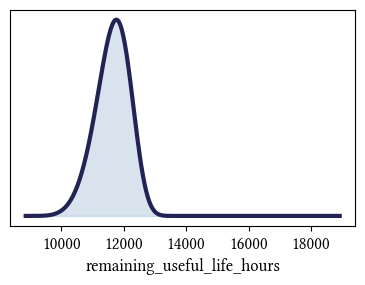

feasible at 1%   (max ~ 17% of rows)


In [32]:
pdf = make_pdf(COMPONENTS)
p = target_props(COMPONENTS, centers)          # target proportion per bin
if p is None:
    raise ValueError("the mixture puts no mass on the target's range -- adjust COMPONENTS")
target = {b: float(p[b]) for b in range(n_bins)}

xs = np.linspace(tmin, tmax, 400)
ys = np.array([pdf(x) for x in xs])
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
ax.plot(xs, ys, color=CB_palette["CBdarkblue"])
ax.fill_between(xs, ys, color=CB_palette["CBblue"], alpha=0.2)
ax.set_xlabel(TARGET); ax.set_yticks([])
fig.tight_layout(pad=0.1)
save_pdf(fig, fig_path(dist_tag(COMPONENTS)))
plt.show()

ok, max_pct, b, need, have = feasibility(p, avail, N, CARDINALITY_PCT)
if ok:
    print(f"feasible at {CARDINALITY_PCT}%   (max ~ {max_pct:.0f}% of rows)")
else:
    print(f"INFEASIBLE at {CARDINALITY_PCT}%: bin {b} needs {need:.0f} rows but has {have}"
          f"   (max ~ {max_pct:.0f}%)")

### Plot + report helpers

`show(result, label)` draws what the UI's bottom panel draws (full-data histogram,
the subset's histogram and the specified pdf), then prints the metrics and the rule.
With `SAVE_PDF = True`, the best subset's figure (index 0) is written to `FIG_DIR` as
`{title}_{distribution}_cardinality_{pct}pct.pdf` or `{title}_{distribution}_term_{K}.pdf`.

In [33]:
def metrics_of(res):
    return dist_metrics(res["got"], res["tc"])

def show(res, label, query, save=False, max_terms=20):
    """query: "cardinality" or "term".  save: write the PDF (if SAVE_PDF)."""
    rows = res["rows"]
    sel = df[TARGET].to_numpy()[rows]
    m = metrics_of(res)
    simple = res["simple"]
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.hist(df[TARGET], bins=edges, density=True, alpha=0.35,
            color=CB_palette["CBblue"], label="full")
    if len(sel):
        ax.hist(sel, bins=edges, density=True, alpha=0.75,
                color=CB_palette["CBred"], label="subset")
    ax.plot(xs, ys, "--", color=CB_palette["CBdarkgrey"], label="target pdf")
    ax.set_xlabel(TARGET); ax.set_yticks([]); ax.legend(frameon=False)
    fig.tight_layout(pad=0.3)
    if save:
        detail = (f"cardinality_{_num(CARDINALITY_PCT)}pct" if query == "cardinality"
                  else f"term_{N_BOXES}")
        save_pdf(fig, fig_path(dist_tag(COMPONENTS), detail))
    plt.show()
    print(f"{label}: rows {len(sel)} / {N}   terms {simple['n_terms']} "
          f"(tree: {res['red']['n_terms']})   literals {simple['n_literals']}   " +
          "   ".join(f"{k.upper()}={v}" for k, v in m.items()))
    print(rule_to_str(simple, max_terms=max_terms))
    # res["simple"]["expr"] holds the same rule as a sympy expression

def table(results, labels):
    return pd.DataFrame([dict(result=l, rows=len(r["rows"]), terms=r["simple"]["n_terms"],
                              literals=r["simple"]["n_literals"],
                              tree_terms=r["red"]["n_terms"], **metrics_of(r))
                         for r, l in zip(results, labels)])

## 6a. Query by cardinality

Disjoint subsets of `CARDINALITY_PCT`% of the rows, each matching the target,
extracted greedily until the next one's TVD exceeds `TVD_THRESHOLD`. Each
subset's tree rule is reduced with sympy (repeated tests on a feature collapse
to one interval; neighbouring boxes merge), and the results are sorted shortest
simplified rule first (`RANK_BY`). `tree_terms` is the length before reduction.

In [34]:
total = round(CARDINALITY_PCT / 100 * N)
t0 = time.perf_counter()
found = find_multiple_subsets(ix, target, total, TVD_THRESHOLD)
query_sec = time.perf_counter() - t0
t0 = time.perf_counter()
subsets = rank_by_rule_length(found, by=RANK_BY)
print(f"{len(subsets)} disjoint subset(s) under TVD {TVD_THRESHOLD} in {query_sec:.2f}s; "
      f"simplified + sorted by {RANK_BY} in {time.perf_counter() - t0:.2f}s")
table(subsets, [f"subset #{i + 1}" for i in range(len(subsets))])

17 disjoint subset(s) under TVD 0.05 in 12.78s; simplified + sorted by terms in 5.05s


,result,rows,terms,literals,tree_terms,tvd,jsd,kld,hellinger,bc
0,subset #1,1004,35,370,35,0.0083,0.0017,0.0567,0.0402,0.9984
1,subset #2,1004,39,445,39,0.0083,0.0017,0.0567,0.0402,0.9984
2,subset #3,1004,41,444,41,0.0083,0.0017,0.0567,0.0402,0.9984
3,subset #4,1004,43,484,43,0.0083,0.0017,0.0567,0.0402,0.9984
4,subset #5,1004,44,448,44,0.0083,0.0017,0.0567,0.0402,0.9984
5,subset #6,1004,49,551,49,0.0083,0.0017,0.0567,0.0402,0.9984
6,subset #7,1004,52,613,52,0.0083,0.0017,0.0567,0.0402,0.9984
7,subset #8,1004,57,663,57,0.0083,0.0017,0.0567,0.0402,0.9984
8,subset #9,1004,77,932,77,0.0083,0.0017,0.0567,0.0402,0.9984
9,subset #10,1004,82,1073,82,0.0083,0.0017,0.0567,0.0402,0.9984


saved figures/factory_weibull-shape5p75-scale3000-loc8856-w1_cardinality_1pct.pdf


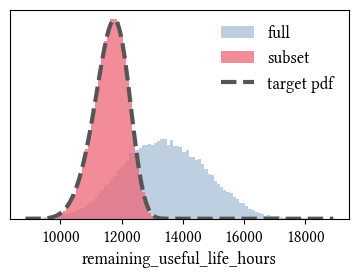

subset #1: rows 1004 / 100000   terms 35 (tree: 35)   literals 370   TVD=0.0083   JSD=0.0017   KLD=0.0567   HELLINGER=0.0402   BC=0.9984
(bearing_health <= 65.150 AND days_since_maintenance > 57.150 AND failure_frequency <= 0.740 AND hydraulic_health <= 79.750 AND machine_power_kw <= 47.000 AND motor_health <= 89.850 AND motor_temperature_c <= 70.450 AND pump_health <= 84.950)
  OR (bearing_health <= 65.150 AND cooling_system_health <= 94.050 AND days_since_maintenance > 57.150 AND failure_frequency > 0.740 AND hydraulic_health <= 79.750 AND machine_type <= 6.500 AND machine_weight_kg <= 6772.900 AND motor_health <= 89.850 AND motor_temperature_c <= 70.450 AND oil_temperature_c <= 52.950 AND pump_health <= 84.950)
  OR (bearing_health <= 65.150 AND cooling_system_health > 94.050 AND days_since_maintenance > 57.150 AND failure_frequency > 0.740 AND hydraulic_health <= 79.750 AND machine_weight_kg <= 6772.900 AND motor_health <= 89.850 AND motor_temperature_c <= 70.450 AND pump_health <=

In [35]:
SHOW = 0          # which subset to plot (0 = the first / best)
if subsets:
    show(subsets[SHOW], f"subset #{SHOW + 1}", query="cardinality", save=(SHOW == 0))
else:
    print("no subset under the TVD threshold -- raise TVD_THRESHOLD or lower CARDINALITY_PCT")

## 6b. Query by number of boxes

Disjoint subsets of exactly `N_BOXES` boxes (one DNF conjunct each), run to
exhaustion: the `N_BOXES` boxes whose union is closest to the target in TVD,
then the best `N_BOXES` among the leaves not yet used, and so on, until the next
result's TVD exceeds `TVD_THRESHOLD` or fewer than `N_BOXES` disjoint boxes are
left. There is no size constraint, so subsets can differ in rows. Each rule is
reduced with sympy (touching boxes can merge, leaving fewer than `N_BOXES`
terms) and the results are sorted shortest simplified rule first (`RANK_BY`).

In [36]:
t0 = time.perf_counter()
box_found = find_multiple_box_subsets(ix, target, N_BOXES, TVD_THRESHOLD)
query_sec = time.perf_counter() - t0
t0 = time.perf_counter()
box_subsets = rank_by_rule_length(box_found, by=RANK_BY)
print(f"{len(box_subsets)} disjoint {N_BOXES}-box subset(s) under TVD {TVD_THRESHOLD} "
      f"in {query_sec:.2f}s; simplified + sorted by {RANK_BY} in "
      f"{time.perf_counter() - t0:.2f}s")
table(box_subsets, [f"{N_BOXES}-box #{i + 1}" for i in range(len(box_subsets))])

5 disjoint 4-box subset(s) under TVD 0.05 in 464.71s; simplified + sorted by terms in 0.04s


,result,rows,terms,literals,tree_terms,tvd,jsd,kld,hellinger,bc
0,4-box #1,722,4,36,4,0.0429,0.0056,0.0581,0.0657,0.9957
1,4-box #2,1021,4,38,4,0.0377,0.0047,0.0392,0.0599,0.9964
2,4-box #3,1131,4,40,4,0.0375,0.0061,0.0510,0.0718,0.9948
3,4-box #4,1072,4,41,4,0.0435,0.0065,0.0512,0.0697,0.9951
4,4-box #5,817,4,42,4,0.0452,0.0068,0.0410,0.0719,0.9948


saved figures/factory_weibull-shape5p75-scale3000-loc8856-w1_term_4.pdf


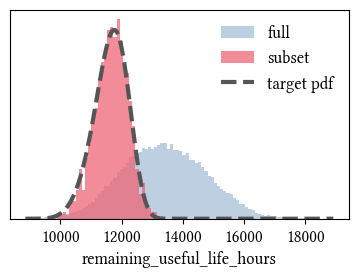

4-box #1: rows 722 / 100000   terms 4 (tree: 4)   literals 36   TVD=0.0429   JSD=0.0056   KLD=0.0581   HELLINGER=0.0657   BC=0.9957
(66.850 < bearing_health <= 81.450 AND days_since_maintenance > 80.150 AND electrical_health <= 82.150 AND hydraulic_health > 81.650 AND motor_temperature_c > 70.450 AND pump_health <= 69.050)
  OR (bearing_health <= 70.050 AND days_since_maintenance > 50.500 AND electrical_health <= 88.950 AND hydraulic_health > 79.750 AND motor_health <= 73.700 AND motor_temperature_c <= 70.450 AND 65.000 < pump_health <= 78.050)
  OR (69.550 < bearing_health <= 81.450 AND cooling_system_health <= 88.100 AND days_since_maintenance <= 80.150 AND days_since_previous_failure > 262.500 AND hydraulic_health > 89.550 AND last_maintenance_date <= 64.500 AND machine_power_kw > 42.350 AND motor_health <= 63.550 AND motor_temperature_c > 70.450 AND production_cycles <= 377241.500 AND pump_health <= 82.550)
  OR (68.650 < bearing_health <= 81.450 AND cooling_system_health <= 74.400

In [37]:
SHOW_BOX = 0      # which box subset to plot (0 = shortest rule)
if box_subsets:
    show(box_subsets[SHOW_BOX], f"{N_BOXES}-box #{SHOW_BOX + 1}", query="term",
         save=(SHOW_BOX == 0))
else:
    print("no box subset under the TVD threshold -- raise TVD_THRESHOLD or change N_BOXES")

## 7. Best cardinality subset and 1–3 term subsets (saved)

The best cardinality subset (section 6a) next to the best subsets of the
term-restricted query for K = 1, 2, 3 (each K with its own TVD threshold), in one
full-width figure. The figure and each best rule with its metrics are written to
`FIG_DIR`.

K=1: 2 subset(s) under TVD 0.125 in 4.7s


K=2: 11 subset(s) under TVD 0.1 in 310.3s
K=3: 7 subset(s) under TVD 0.075 in 400.7s
saved figures/factory_weibull-shape5p75-scale3000-loc8856-w1_cardinality_1pct_term_1to3.pdf
saved figures/factory_weibull-shape5p75-scale3000-loc8856-w1_cardinality_1pct_term_1to3.txt


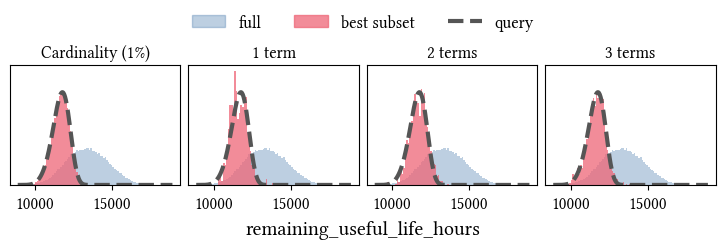

In [38]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

TERM_THRESHOLDS = {1: 0.125, 2: 0.1, 3: 0.075}   # K -> TVD threshold for the term query

def describe(heading, threshold, n_found, b):
    """Report lines for one panel's best subset."""
    lines = [f"=== {heading} (TVD threshold {threshold}) ==="]
    if b is None:
        return lines + [f"no subset with TVD <= {threshold}", ""]
    return lines + [
        f"subsets found: {n_found}   best: rank 1 (sorted by {RANK_BY})",
        f"rows: {len(b['rows'])} / {N}   terms: {b['simple']['n_terms']} "
        f"(tree: {b['red']['n_terms']})   literals: {b['simple']['n_literals']}",
        "   ".join(f"{key.upper()}={v}" for key, v in metrics_of(b).items()),
        "rule:", rule_to_str(b["simple"], max_terms=b["simple"]["n_terms"]), ""]

# panel 1: best cardinality subset (from section 6a)
best_c = subsets[0] if subsets else None
panels = [(f"Cardinality ({_num(CARDINALITY_PCT).replace('p', '.')}%)", best_c)]
report = describe(f"cardinality query, {CARDINALITY_PCT}% of rows", TVD_THRESHOLD,
                  len(subsets), best_c)

# panels 2-4: best term-restricted subset for each K
for k, thr in TERM_THRESHOLDS.items():
    t0 = time.perf_counter()
    ranked = rank_by_rule_length(find_multiple_box_subsets(ix, target, k, thr), by=RANK_BY)
    print(f"K={k}: {len(ranked)} subset(s) under TVD {thr} "
          f"in {time.perf_counter() - t0:.1f}s")
    best = ranked[0] if ranked else None
    panels.append((f"{k} term" + ("s" if k > 1 else ""), best))
    report += describe(f"term-restricted query, K = {k}", thr, len(ranked), best)

full = df[TARGET].to_numpy()
c_full, c_sub, c_q = CB_palette["CBblue"], CB_palette["CBred"], CB_palette["CBdarkgrey"]
fig, axs = plt.subplots(1, len(panels), sharex=True, sharey=True, layout="constrained",
                        figsize=(text_width, text_width / len(panels) * ASPECT + 1.05))
# + 1.05 in for the legend, panel titles, tick labels and x label
for ax, (title, b) in zip(axs, panels):
    ax.hist(full, bins=edges, density=True, alpha=0.35, color=c_full)
    if b is not None:
        ax.hist(full[b["rows"]], bins=edges, density=True, alpha=0.75, color=c_sub)
    else:
        ax.text(0.5, 0.5, "none", transform=ax.transAxes, ha="center", va="center")
    ax.plot(xs, ys, "--", color=c_q)
    ax.set_title(title)
    ax.set_yticks([]); ax.locator_params(axis="x", nbins=3)
fig.supxlabel(TARGET)
fig.legend(handles=[Patch(color=c_full, alpha=0.35, label="full"),
                    Patch(color=c_sub, alpha=0.75, label="best subset"),
                    Line2D([], [], color=c_q, linestyle="--", label="query")],
           loc="outside upper center", ncol=3, frameon=False)

ks = list(TERM_THRESHOLDS)
path = fig_path(dist_tag(COMPONENTS), f"cardinality_{_num(CARDINALITY_PCT)}pct",
                f"term_{min(ks)}to{max(ks)}")
Path(path).parent.mkdir(parents=True, exist_ok=True)
fig.savefig(path)                        # exactly 516 pt wide: no bbox_inches="tight"
txt = Path(path).with_suffix(".txt")
txt.write_text("\n".join([f"dataset: {name}   target: {TARGET}   N={N}",
                          f"query: {COMPONENTS}",
                          f"ranked by {RANK_BY}", ""] + report) + "\n")
print(f"saved {path}\nsaved {txt}")
plt.show()

## 8. Comparing two query distributions (saved)

A Weibull and a log-normal query distribution side by side in one figure at column
width (252 pt), on shared axes.

In [ ]:
COMPARE = [
    ("weibull",   {"shape": 5.75, "scale": 3000, "loc": tmin}, 1.0),
    ("lognormal", {"mu": 6.8, "sigma": 0.6, "loc": 15000}, 1.0),
]
TITLES = {"weibull": "Weibull", "lognormal": "log-normal"}
colors = [CB_palette["CBblue"], CB_palette["CBred"]]

xs_c = np.linspace(tmin, tmax, 800)
fig, axs = plt.subplots(1, len(COMPARE), sharex=True, sharey=True, layout="constrained",
                        figsize=(fig_width, fig_width / len(COMPARE) * ASPECT + 0.6))
# + 0.6 in for the panel titles, tick labels and x label
for ax, (fam, params, _w), col in zip(axs, COMPARE, colors):    # each drawn as its own pdf
    y = make_pdf((fam, params))(xs_c)
    ax.plot(xs_c, y, color=col)
    ax.fill_between(xs_c, y, color=col, alpha=0.15)
    ax.set_title(TITLES.get(fam, fam))
    ax.set_yticks([]); ax.locator_params(axis="x", nbins=3)
fig.supxlabel(TARGET)

path = fig_path("_vs_".join(dist_tag([c]) for c in COMPARE))
Path(path).parent.mkdir(parents=True, exist_ok=True)
fig.savefig(path)                        # exactly 252 pt wide: no bbox_inches="tight"
print(f"saved {path}")
plt.show()